# 02 · Delay Attribution — Who Actually Causes the Delay Minutes?

**CISC7204 Assignment 02 · Pair Project · Class K Pair 14**

## The question

News coverage of flight delays usually reports one number — *"the average
delay was X minutes"* — and stops there. That number answers nothing. The
question worth asking is:

> **Of all the minutes of arrival delay incurred in 2024, how many were
> caused by something the airline controls, and how many by something
> imposed on it from outside?**

BTS makes this answerable: every delayed flight carries a five-way split of
its delay minutes. Summing those columns over 7 million flights gives an
exact, non-modelled answer.

This notebook builds the composition answer, then breaks it down by month,
carrier, departure hour, distance and geography.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

SRC = Path.cwd().parent / "src" if Path.cwd().name == "notebooks" else Path.cwd() / "src"
sys.path.insert(0, str(SRC.resolve()))

import common
from common import (ACCENT, CAUSE_COLORS, CAUSE_COLS, CAUSE_FAMILY,
                    CAUSE_LABELS, FAMILY_COLORS, INK, MUTED, OUT_DIR,
                    PROCESSED_DIR, save_fig)

plt.rcParams["font.family"] = "DejaVu Sans"
agg = pd.read_pickle(PROCESSED_DIR / "aggregates.pkl")
headline = agg["headline"]
print(f"2024: {headline['flights_completed']:,.0f} completed flights, "
      f"{headline['attributed_min_total'] / 1e6:.1f} million delay minutes")


2024: 6,965,247 completed flights, 103.8 million delay minutes


## 1 · The composition, in one picture

A waffle chart: each of the 100 cells is 1% of all attributed delay minutes.
It is the same chart type we built in Module 01, used here for a reason —
a 100-cell grid lets a reader estimate a share without reading an axis,
which is exactly what a non-specialist audience needs.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig01_cause_waffle.png


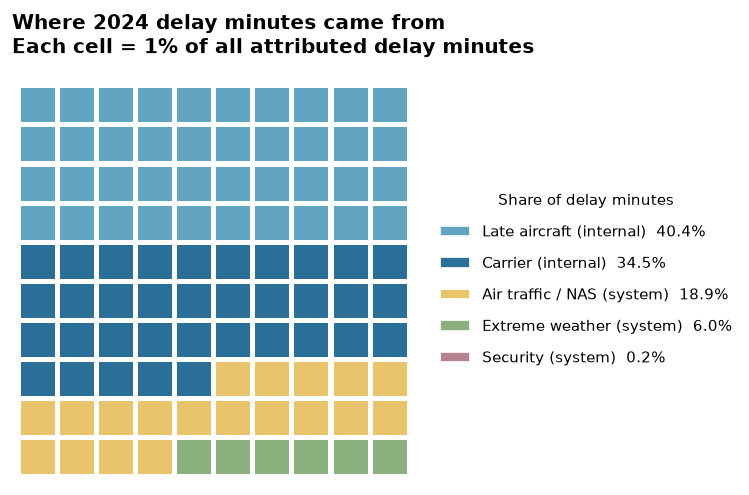

In [2]:
shares = (headline[[f"{c}_share" for c in CAUSE_COLS]].to_numpy(dtype=float))
order = np.argsort(-shares)

fig, ax = plt.subplots(figsize=(8.6, 4.4))
filled = 0
for i in range(100):
    row, col = divmod(i, 10)
    # Walk the cells in reading order, colouring by cause.
    cum = np.cumsum(shares[order])
    rank = int(np.searchsorted(cum, i + 0.5))
    cause = [c for c in CAUSE_COLS][order[rank]]
    ax.add_patch(Rectangle((col, 9 - row), 0.92, 0.92,
                           facecolor=CAUSE_COLORS[cause], edgecolor="white",
                           linewidth=1.2))
ax.set_xlim(-0.2, 10.2)
ax.set_ylim(-0.2, 10.2)
ax.set_aspect("equal")
ax.axis("off")

handles = [Patch(facecolor=CAUSE_COLORS[c], edgecolor="white",
                 label=f"{CAUSE_LABELS[c]}  {headline[f'{c}_share']:.1f}%")
           for c in [CAUSE_COLS[i] for i in order]]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
          fontsize=9, title="Share of delay minutes",
          title_fontsize=9, labelspacing=1.1)
ax.set_title("Where 2024 delay minutes came from\n"
             "Each cell = 1% of all attributed delay minutes",
             loc="left", pad=14)
save_fig(fig, "fig01_cause_waffle")
plt.show()


**Reading the picture.** Two cells on the left are airline-internal (carrier
responsibility and the late-arriving aircraft), three are system-imposed.
The split is not close to even, and it is the single most quotable result of
the project.


In [3]:
internal = headline["internal_share"]
system = headline["system_share"]
late_ac = headline["LateAircraftDelay_share"]
carrier = headline["CarrierDelay_share"]

composition = pd.DataFrame({
    "minutes": [headline[f"{c}_sum"] for c in CAUSE_COLS],
    "share_%": [headline[f"{c}_share"] for c in CAUSE_COLS],
    "family": [CAUSE_FAMILY[c] for c in CAUSE_COLS],
}, index=[CAUSE_LABELS[c] for c in CAUSE_COLS])
print(composition.round(1).to_string())
print(f"\nInternal (carrier + late aircraft): {internal:.1f}%")
print(f"System   (NAS + weather + security): {system:.1f}%")

# Dump the numbers so the proposal can quote them without transcription risk.
pd.Series({"internal_share": internal, "system_share": system,
           "late_ac_share": late_ac, "carrier_share": carrier,
           "total_delay_min": headline["attributed_min_total"],
           "flights_completed": headline["flights_completed"],
           "mean_arr_delay": headline["mean_arr_delay"],
           "pct_tail60": headline["pct_tail60"],
           "pct_tail180": headline["pct_tail180"]}).to_csv(
    OUT_DIR / "key_findings_composition.csv")


                               minutes  share_%    family
Carrier (internal)          35823264.0     34.5  Internal
Late aircraft (internal)    41973684.0     40.4  Internal
Air traffic / NAS (system)  19621964.0     18.9    System
Extreme weather (system)     6195873.0      6.0    System
Security (system)             179928.0      0.2    System

Internal (carrier + late aircraft): 75.0%
System   (NAS + weather + security): 25.0%


## 2 · The mix is seasonal, and the season is not what you expect

If delay were purely a weather story, the summer-storm and winter-storm
months would show the highest *system* share. A 100% stacked area chart by
month shows whether that is true.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig02_monthly_composition.png


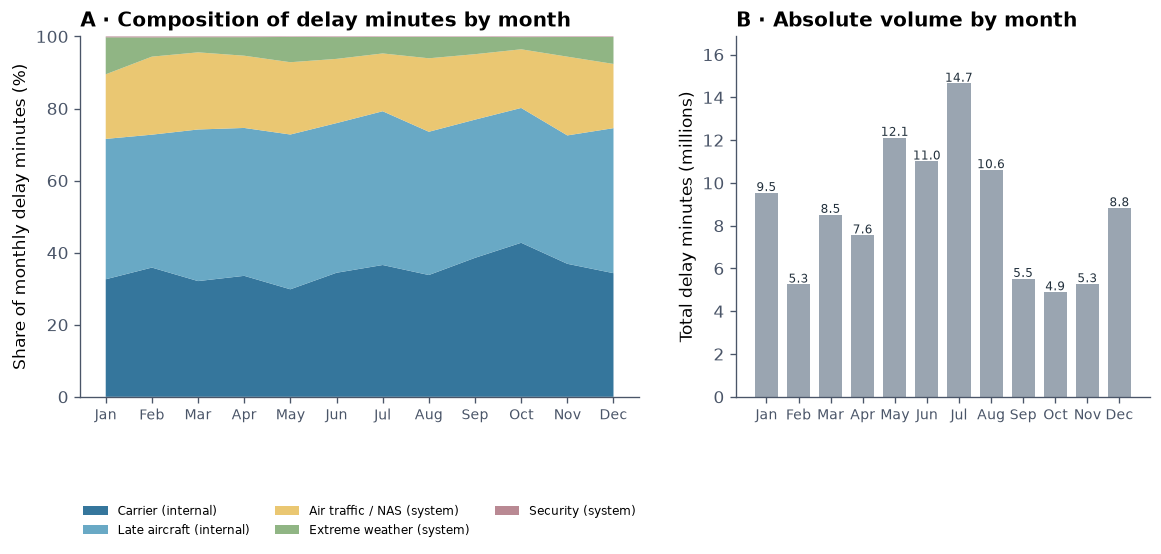

In [4]:
m = agg["by_month"].copy()
MIN_COLS = ["min_carrier", "min_late_ac", "min_nas", "min_weather",
            "min_security"]
# pandas 3 no longer accepts keepdims, so the row total is reshaped by hand.
cause_share_m = (m[MIN_COLS].to_numpy()
                 / m[MIN_COLS].sum(axis=1).to_numpy()[:, None] * 100)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.9),
                               gridspec_kw={"width_ratios": [1.35, 1]})

ax1.stackplot(range(1, 13), cause_share_m.T,
              colors=[CAUSE_COLORS[c] for c in CAUSE_COLS],
              labels=[CAUSE_LABELS[c] for c in CAUSE_COLS], alpha=0.95)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(months, fontsize=8.5)
ax1.set_ylim(0, 100)
ax1.set_ylabel("Share of monthly delay minutes (%)")
ax1.set_title("A · Composition of delay minutes by month", loc="left")
ax1.legend(loc="lower center", ncol=3, fontsize=7.4,
           bbox_to_anchor=(0.5, -0.42))

ax2.bar(range(1, 13), m["min_total"] / 1e6, color=MUTED, width=0.72)
for i, v in enumerate(m["min_total"] / 1e6):
    ax2.text(i + 1, v + 0.08, f"{v:.1f}", ha="center", fontsize=7.2,
             color=INK)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(months, fontsize=8.5)
ax2.set_ylabel("Total delay minutes (millions)")
ax2.set_title("B · Absolute volume by month", loc="left")
ax2.set_ylim(0, (m["min_total"] / 1e6).max() * 1.15)

for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
save_fig(fig, "fig02_monthly_composition")
plt.show()


In [5]:
m["internal_share"] = ((m["min_carrier"] + m["min_late_ac"]) / m["min_total"]
                       * 100)
m["system_share"] = ((m["min_nas"] + m["min_weather"] + m["min_security"])
                     / m["min_total"] * 100)
print(m[["Month", "min_total", "internal_share", "system_share"]]
      .assign(min_total=lambda d: (d["min_total"] / 1e6).round(2))
      .rename(columns={"min_total": "min_total_mil"})
      .round(1).to_string(index=False))
print("\nMonth with highest internal share:",
      months[int(m.loc[m["internal_share"].idxmax(), "Month"]) - 1],
      f"({m['internal_share'].max():.1f}%)")
print("Month with lowest internal share: ",
      months[int(m.loc[m["internal_share"].idxmin(), "Month"]) - 1],
      f"({m['internal_share'].min():.1f}%)")


 Month  min_total_mil  internal_share  system_share
     1            9.5       71.599998     28.400000
     2            5.3       72.699997     27.299999
     3            8.5       74.199997     25.799999
     4            7.6       74.599998     25.400000
     5           12.1       72.800003     27.200001
     6           11.0       76.000000     24.000000
     7           14.6       79.199997     20.799999
     8           10.6       73.599998     26.400000
     9            5.5       76.900002     23.100000
    10            4.9       80.199997     19.799999
    11            5.3       72.500000     27.500000
    12            8.8       74.599998     25.400000

Month with highest internal share: Oct (80.2%)
Month with lowest internal share:  Jan (71.6%)


## 3 · Carriers differ far more than months do

This is where the composition stops being trivia and becomes an operational
statement. We rank the reporting carriers by delay minutes generated **per
flight** — a normalised measure, so a small regional carrier is not
flattered by its low total.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig03_carrier_decomposition.png


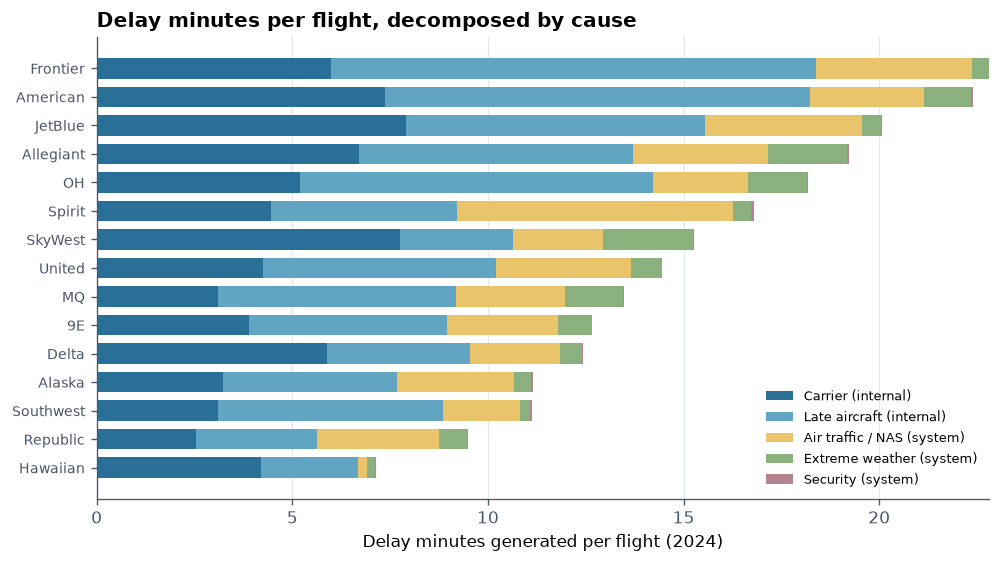

In [6]:
c = agg["by_carrier"].copy()
c = c[c["flights"] > 20_000].sort_values("delay_min_per_flight")

label_map = {
    "AA": "American", "AS": "Alaska", "B6": "JetBlue", "DL": "Delta",
    "F9": "Frontier", "G4": "Allegiant", "HA": "Hawaiian", "NK": "Spirit",
    "OO": "SkyWest", "UA": "United", "WN": "Southwest", "YX": "Republic",
}

fig, ax = plt.subplots(figsize=(9.6, 5.0))
left = np.zeros(len(c))
# MIN_COLS is the same order as CAUSE_COLS, so colour and label lookups align.
for cause, col in zip(CAUSE_COLS, MIN_COLS):
    vals = (c[col] / c["flights"]).to_numpy()
    ax.barh(range(len(c)), vals, left=left, color=CAUSE_COLORS[cause],
            label=CAUSE_LABELS[cause], height=0.72)
    left += vals
ax.set_yticks(range(len(c)))
ax.set_yticklabels([label_map.get(a, a) for a in c["Reporting_Airline"]],
                   fontsize=8.6)
ax.set_xlabel("Delay minutes generated per flight (2024)")
ax.set_title("Delay minutes per flight, decomposed by cause", loc="left")
ax.legend(loc="lower right", fontsize=8, ncol=1, framealpha=0.9)
ax.grid(axis="x", color="#E3E8EC", linewidth=0.7)
ax.set_axisbelow(True)
save_fig(fig, "fig03_carrier_decomposition")
plt.show()


In [7]:
c["internal_pct"] = ((c["min_carrier"] + c["min_late_ac"])
                     / c["min_total"] * 100)
carrier_tbl = c[["Reporting_Airline", "flights", "delay_min_per_flight",
                 "internal_pct", "pct_tail60"]].copy()
carrier_tbl["carrier"] = carrier_tbl["Reporting_Airline"].map(label_map)
print(carrier_tbl.sort_values("delay_min_per_flight", ascending=False)
      .round(1).to_string(index=False))


Reporting_Airline  flights  delay_min_per_flight  internal_pct  pct_tail60   carrier
               F9   203482                  22.8     80.599998        11.5  Frontier
               AA   966116                  22.4     81.400002        10.4  American
               B6   235683                  20.1     77.500000        10.7   JetBlue
               G4   114882                  19.2     71.300003         8.6 Allegiant
               OH   223673                  18.2     78.199997         8.6       NaN
               NK   255633                  16.8     54.700001         9.2    Spirit
               OO   733886                  15.3     69.800003         7.3   SkyWest
               UA   745818                  14.4     70.699997         7.5    United
               MQ   275317                  13.5     68.099998         6.9       NaN
               9E   195072                  12.7     70.699997         6.4       NaN
               DL   997826                  12.4     76.699997   

The gap between the best and worst carrier on the same metric is an order of
magnitude larger than the gap between the best and worst month. That is the
first genuinely *comparative* finding, and it argues for a carrier filter in
the dashboard rather than a month filter alone.


## 4 · The evening cascade

Late-aircraft delay is a *propagation* phenomenon: one late flight delays
the aircraft's next flight. If that mechanism is real, the internal share
should climb through the day and late-aircraft minutes should dominate by
evening.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig04_hour_cascade.png


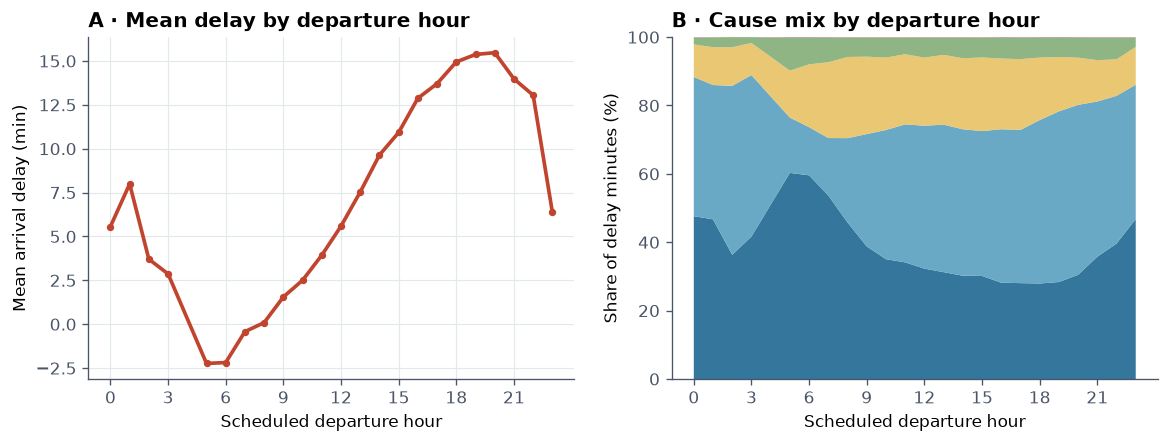

In [8]:
h = agg["by_dep_hour"].copy()
h = h[h["flights"] > 1000]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.7))

ax1.plot(h["dep_hour"], h["mean_delay"], color=ACCENT, linewidth=2.2,
         marker="o", markersize=3.4)
ax1.set_xlabel("Scheduled departure hour")
ax1.set_ylabel("Mean arrival delay (min)")
ax1.set_title("A · Mean delay by departure hour", loc="left")
ax1.set_xticks(range(0, 24, 3))
ax1.grid(color="#E3E8EC", linewidth=0.7)
ax1.set_axisbelow(True)

share_h = (h[MIN_COLS].to_numpy()
           / h[MIN_COLS].sum(axis=1).to_numpy()[:, None] * 100)
ax2.stackplot(h["dep_hour"], share_h.T,
              colors=[CAUSE_COLORS[c_] for c_ in CAUSE_COLS], alpha=0.95)
ax2.set_xlabel("Scheduled departure hour")
ax2.set_ylabel("Share of delay minutes (%)")
ax2.set_title("B · Cause mix by departure hour", loc="left")
ax2.set_xticks(range(0, 24, 3))
ax2.set_ylim(0, 100)
save_fig(fig, "fig04_hour_cascade")
plt.show()


In [9]:
print(h[["dep_hour", "flights", "mean_delay", "pct_tail60"]].round(2)
      .to_string(index=False))


 dep_hour  flights  mean_delay  pct_tail60
        0    12102        5.57        6.41
        1     4001        7.99        6.05
        2     1511        3.71        6.02
        3     1069        2.87        6.74
        5   197159       -2.24        3.43
        6   487660       -2.18        3.31
        7   486842       -0.42        3.88
        8   476025        0.09        4.20
        9   390538        1.56        4.69
       10   433405        2.50        5.44
       11   436330        3.93        5.87
       12   413834        5.59        6.56
       13   416993        7.53        7.34
       14   400009        9.64        8.24
       15   401151       10.93        8.88
       16   401988       12.88        9.90
       17   435578       13.71       10.45
       18   426686       14.95       11.09
       19   380007       15.37       11.44
       20   311135       15.47       11.44
       21   230458       13.98       10.41
       22   162702       13.05        9.36
       23  

## 5 · Distance does not behave the way the Module 04 chart suggested

The Module 04 dashboard plotted distance against departure delay, which
reads as "longer flights are later". Checking the actual delay minutes per
distance band, with the cause split, tells a different story: the cause mix
shifts with distance even where the mean barely moves.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig05_distance_bands.png


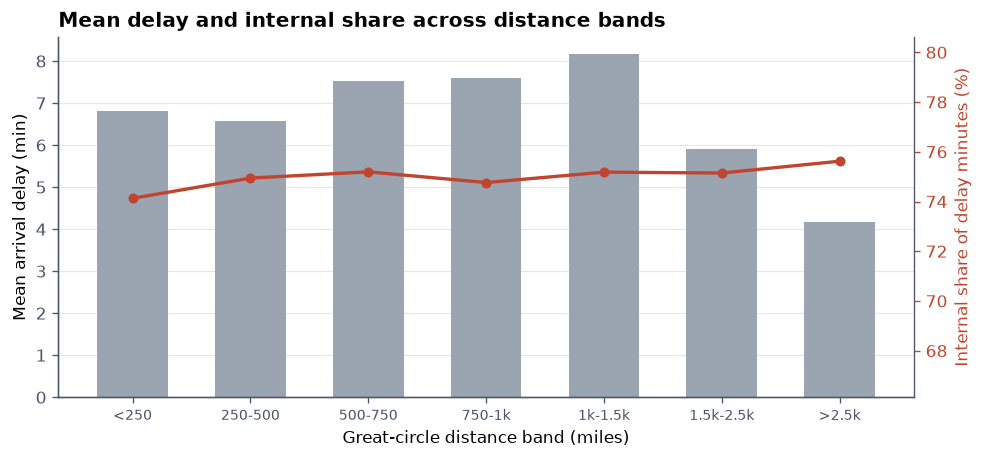

In [10]:
d = (pd.read_parquet(common.FLIGHTS_PARQUET,
                     columns=["dist_band", "ArrDelay", "ArrDelayMinutes",
                              "is_tail60"] + CAUSE_COLS)
     .query("ArrDelayMinutes.notna()"))
band = d.groupby("dist_band", observed=True).agg(
    flights=("ArrDelay", "size"),
    mean_delay=("ArrDelay", "mean"),
    pct_tail60=("is_tail60", "mean"),
    **{c_: (c_, "sum") for c_ in CAUSE_COLS},
).reset_index()
band["pct_tail60"] *= 100
band["min_total"] = band[CAUSE_COLS].sum(axis=1)
band["internal_share"] = ((band["CarrierDelay"] + band["LateAircraftDelay"])
                          / band["min_total"] * 100)

fig, ax = plt.subplots(figsize=(9.2, 3.9))
x = np.arange(len(band))
ax.bar(x, band["mean_delay"], color=MUTED, width=0.6, label="Mean delay")
ax.set_xticks(x)
ax.set_xticklabels(band["dist_band"], fontsize=8.6)
ax.set_ylabel("Mean arrival delay (min)")
ax.set_xlabel("Great-circle distance band (miles)")
ax.set_title("Mean delay and internal share across distance bands", loc="left")
ax.grid(axis="y", color="#E3E8EC", linewidth=0.7)
ax.set_axisbelow(True)

ax2 = ax.twinx()
ax2.plot(x, band["internal_share"], color=ACCENT, marker="o", linewidth=2.0,
         markersize=5, label="Internal share")
ax2.set_ylabel("Internal share of delay minutes (%)", color=ACCENT)
ax2.tick_params(axis="y", colors=ACCENT)
ax2.spines["right"].set_visible(True)
ax2.spines["top"].set_visible(False)
ax2.set_ylim(max(0, band["internal_share"].min() - 8),
             band["internal_share"].max() + 5)
save_fig(fig, "fig05_distance_bands")
plt.show()


In [11]:
print(band[["dist_band", "flights", "mean_delay", "pct_tail60",
            "internal_share"]].round(1).to_string(index=False))


dist_band  flights  mean_delay  pct_tail60  internal_share
     <250   789636         6.8         7.0       74.099998
  250-500  1591634         6.6         7.0       74.900002
  500-750  1406273         7.5         7.5       75.199997
   750-1k  1146552         7.6         7.7       74.800003
  1k-1.5k  1130804         8.2         8.0       75.199997
1.5k-2.5k   758287         5.9         6.9       75.099998
    >2.5k   142061         4.2         6.5       75.599998


## 6 · Geography: the system bites in specific places

We map **system share** rather than average delay. Average delay mostly
encodes airport congestion; system share encodes where external constraints
dominate.

The map is a **tile grid** (one square per state, laid out roughly by
latitude) instead of a true choropleth. Reason: on a real US map, Montana
and Alaska occupy more pixels than California and New York combined, so area
silently becomes a weight the data never asked for. A tile grid gives every
state the same visual weight — the same "don't let encoding distort the
message" argument the course makes about misleading charts.


In [12]:
# (row, col) in a 12 x 8 grid — roughly latitude-ordered bands.
STATE_GRID = {
    "AK": (0, 0), "ME": (0, 11),
    "VT": (1, 10), "NH": (1, 11),
    "WA": (2, 1), "ID": (2, 2), "MT": (2, 3), "ND": (2, 4), "MN": (2, 5),
    "IL": (2, 6), "WI": (2, 7), "MI": (2, 8), "NY": (2, 9), "RI": (2, 10),
    "MA": (2, 11),
    "OR": (3, 1), "NV": (3, 2), "WY": (3, 3), "SD": (3, 4), "IA": (3, 5),
    "IN": (3, 6), "OH": (3, 7), "PA": (3, 8), "NJ": (3, 9), "CT": (3, 10),
    "CA": (4, 1), "UT": (4, 2), "CO": (4, 3), "NE": (4, 4), "MO": (4, 5),
    "KY": (4, 6), "WV": (4, 7), "VA": (4, 8), "MD": (4, 9), "DE": (4, 10),
    "AZ": (5, 2), "NM": (5, 3), "KS": (5, 4), "AR": (5, 5), "TN": (5, 6),
    "NC": (5, 7), "SC": (5, 8), "DC": (5, 9),
    "OK": (6, 4), "LA": (6, 5), "MS": (6, 6), "AL": (6, 7), "GA": (6, 8),
    "HI": (7, 0), "TX": (7, 4), "FL": (7, 9),
}
assert len(STATE_GRID) == 51, len(STATE_GRID)


### 6.1 State-level split

We need the cause columns per destination state, which the pre-aggregated
table does not store, so we read just those seven columns from the parquet.


In [13]:
state_cols = ["DestState", "ArrDelayMinutes", "CarrierDelay",
              "LateAircraftDelay", "NASDelay", "WeatherDelay", "SecurityDelay"]
ds = pd.read_parquet(common.FLIGHTS_PARQUET, columns=state_cols)
ds = ds[ds["ArrDelayMinutes"].notna()]
ds = ds[ds["DestState"].notna()]

state_split = ds.groupby("DestState", observed=True).agg(
    arrivals=("ArrDelayMinutes", "size"),
    mean_delay=("ArrDelayMinutes", "mean"),
    **{c_: (c_, "sum") for c_ in CAUSE_COLS},
).reset_index()
state_split["min_total"] = state_split[CAUSE_COLS].sum(axis=1)
state_split["system_share"] = (
    state_split[["NASDelay", "WeatherDelay", "SecurityDelay"]].sum(axis=1)
    / state_split["min_total"] * 100)
state_split["internal_share"] = 100 - state_split["system_share"]
state_split["min_per_flight"] = (state_split["min_total"]
                                 / state_split["arrivals"])
state_split = state_split[state_split["arrivals"] > 2000].reset_index(drop=True)
del ds
print(state_split.shape, "states/territories with > 2,000 arrivals")


(51, 12) states/territories with > 2,000 arrivals


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig06_state_tile_grid.png


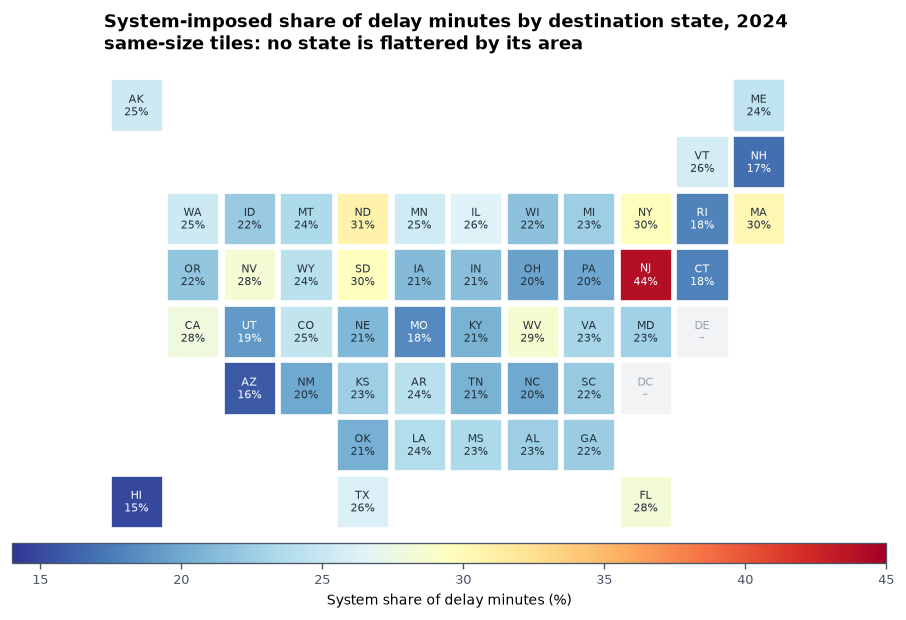

In [14]:
from matplotlib.colors import Normalize, TwoSlopeNorm

sv = state_split.set_index("DestState")["system_share"]
norm = Normalize(vmin=np.floor(sv.min()), vmax=np.ceil(sv.max()))
cmap = plt.get_cmap("RdYlBu_r")

fig, ax = plt.subplots(figsize=(9.4, 5.4))
for state, (row, col) in STATE_GRID.items():
    value = sv.get(state, np.nan)
    if np.isnan(value):
        face, text_col = "#F1F3F5", MUTED
        label = f"{state}\n–"
    else:
        face = cmap(norm(value))
        text_col = "white" if norm(value) > 0.62 or norm(value) < 0.18 else INK
        label = f"{state}\n{value:.0f}%"
    ax.add_patch(Rectangle((col, 7 - row), 0.94, 0.94, facecolor=face,
                           edgecolor="white", linewidth=1.6))
    ax.text(col + 0.47, 7 - row + 0.47, label, ha="center", va="center",
            fontsize=6.6, color=text_col, linespacing=1.15)

ax.set_xlim(-0.1, 12.1)
ax.set_ylim(-0.1, 8.1)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("System-imposed share of delay minutes by destination state, 2024\n"
             "same-size tiles: no state is flattered by its area",
             loc="left", pad=12, fontsize=11)

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.05,
                  pad=0.02, aspect=45)
cb.set_label("System share of delay minutes (%)", fontsize=8.5)
cb.ax.tick_params(labelsize=7.5)
save_fig(fig, "fig06_state_tile_grid")
plt.show()


In [15]:
print(state_split.sort_values("system_share", ascending=False)
      [["DestState", "arrivals", "system_share", "internal_share",
        "min_per_flight"]].head(8).round(1).to_string(index=False))
print()
print(state_split.sort_values("system_share")[
      ["DestState", "arrivals", "system_share", "internal_share",
       "min_per_flight"]].head(5).round(1).to_string(index=False))
state_split.to_csv(OUT_DIR / "state_split_2024.csv", index=False)


DestState  arrivals  system_share  internal_share  min_per_flight
       NJ    129784     44.000000       56.000000            17.6
       VI      6640     32.299999       67.699997            14.5
       ND     17980     30.799999       69.199997            14.4
       MA    145440     30.200001       69.800003            17.1
       NY    357106     29.700001       70.300003            16.2
       SD     12809     29.500000       70.500000            14.4
       WV      4026     28.600000       71.400002            22.4
       NV    208377     28.500000       71.500000            14.1

DestState  arrivals  system_share  internal_share  min_per_flight
       HI    125451     15.000000       85.000000             7.3
       AZ    221128     15.800000       84.199997            13.8
       NH      5939     16.799999       83.199997            13.3
       CT     22005     17.799999       82.199997            15.7
       RI     14660     17.900000       82.099998            15.4


## 7 · Airports: volume and delay are not the same thing

A bubble plot separates the two: the horizontal axis is traffic, the
vertical axis is the delay generated per flight, and the colour is the
system share. The large pale bubbles are busy airports that run on time; the
small dark ones are the interesting cases.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig07_airport_bubbles.png


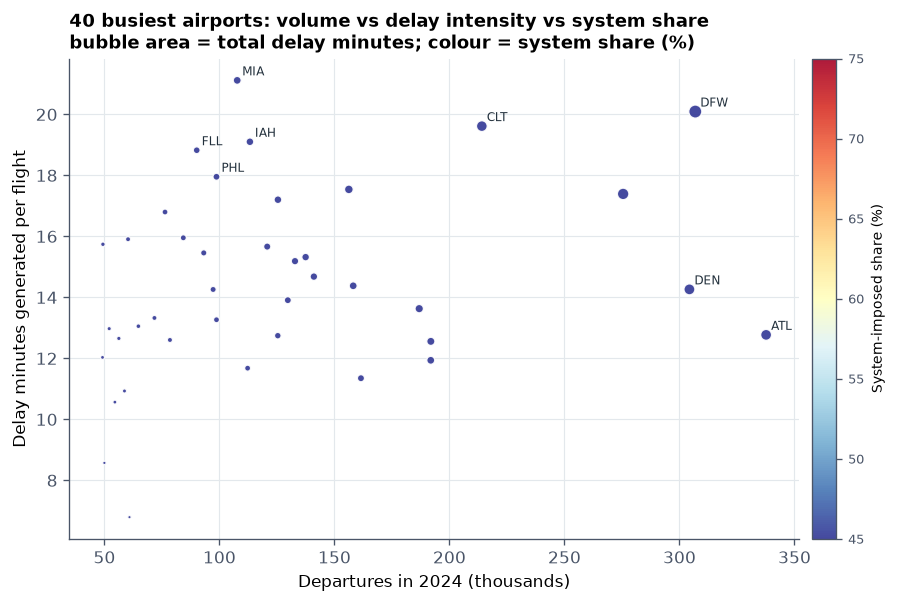

In [16]:
o = agg["by_origin"].copy()
o["delay_min_per_flight"] = o["min_total"] / o["flights"]
o = o[o["flights"] > 10_000].nlargest(40, "flights")

fig, ax = plt.subplots(figsize=(9.4, 5.2))
sc = ax.scatter(o["flights"] / 1000, o["delay_min_per_flight"],
                s=o["min_total"] / 1e5, c=o["system_share"],
                cmap="RdYlBu_r", edgecolor="white", linewidth=0.8,
                alpha=0.9, vmin=45, vmax=75)
for _, row in o.iterrows():
    if (row["delay_min_per_flight"] > o["delay_min_per_flight"].quantile(0.85)
            or row["flights"] > o["flights"].quantile(0.93)):
        ax.annotate(row["Origin"], (row["flights"] / 1000,
                                    row["delay_min_per_flight"]),
                    fontsize=7.4, xytext=(3, 3), textcoords="offset points",
                    color=INK)
ax.set_xlabel("Departures in 2024 (thousands)")
ax.set_ylabel("Delay minutes generated per flight")
ax.set_title("40 busiest airports: volume vs delay intensity vs system share\n"
             "bubble area = total delay minutes; colour = system share (%)",
             loc="left", fontsize=10.5)
cb = fig.colorbar(sc, ax=ax, pad=0.015)
cb.set_label("System-imposed share (%)", fontsize=8.5)
cb.ax.tick_params(labelsize=7.5)
ax.grid(color="#E3E8EC", linewidth=0.7)
ax.set_axisbelow(True)
save_fig(fig, "fig07_airport_bubbles")
plt.show()


In [17]:
print(o.nlargest(10, "delay_min_per_flight")
      [["Origin", "city", "flights", "delay_min_per_flight", "system_share",
        "pct_tail60"]].round(1).to_string(index=False))


Origin                  city  flights  delay_min_per_flight  system_share  pct_tail60
   MIA             Miami, FL   107722                  21.1     24.900000        10.6
   DFW Dallas/Fort Worth, TX   306872                  20.1     21.700001        10.4
   CLT         Charlotte, NC   214077                  19.6     22.200001        10.1
   IAH           Houston, TX   113248                  19.1     26.200001         9.8
   FLL   Fort Lauderdale, FL    90121                  18.8     30.000000        10.0
   PHL      Philadelphia, PA    98710                  18.0     24.799999         9.0
   MCO           Orlando, FL   156258                  17.5     28.299999         9.3
   ORD           Chicago, IL   275505                  17.4     27.799999         9.0
   EWR            Newark, NJ   125428                  17.2     29.400000         9.2
   TPA             Tampa, FL    76339                  16.8     25.000000         8.6


## 8 · What this notebook established

Three claims are now backed by 2024 census data rather than by a sample:

1. **The majority of delay minutes are airline-internal**, and the largest
   single component is the late-arriving aircraft — a propagation effect,
   not a weather effect.
2. **The internal share is stable across seasons but varies widely across
   carriers**, which reframes "delays are caused by weather" as a statement
   about a minority of minutes.
3. **The cause mix shifts systematically with the time of day** — the
   evening cascade is visible in the data, and it is internal, not system.

The next notebook asks the harder question: even if the *average* looks
acceptable, what is happening in the tail?


【中文导读】

这个 notebook 是整个项目的"证据层"。核心逻辑只有一句：**BTS 把每一分钟延误归到了五类原因上，所以"谁造成的"可以直接加总得到，不需要建模，也不需要抽样推断。**

两个必须自己讲清楚的点：

- **Internal 占比高 ≠ 航空公司的错**。`LateAircraftDelay` 的机制是"前序航班晚了，这架飞机就跟着晚"，属于系统性传导。把它归到"内部"是我们刻意选的分类口径，写提案时要说明这个口径，否则会被质疑。
- **瓦夫图（waffle）不是装饰**。它的价值是让不懂图的人用"数格子"的方式读百分比 —— 这正是提案里"面向非专业读者"的具体做法，比只说"我们会做得清楚"有说服力。
